In [16]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import (
    OneHotEncoder,
    StandardScaler,
    SplineTransformer,
)
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error

pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 250)


def locate_project_root():
    candidates = [Path.cwd(), *Path.cwd().parents]

    for candidate in candidates:
        if (
            (candidate / "Data and Resources" / "respondent_scores.csv").exists()
            and (candidate / "Data and Resources" / "final_data.csv").exists()
        ):
            return candidate

    fallback = Path(
        "/Users/albert/Library/CloudStorage/"
        "OneDrive-andrew.cmu.edu/Documents/"
        "CMU 26-27/Undergraduate Research/Victimization/"
        "Code/capstone_victimization"
    )

    if fallback.exists():
        return fallback

    raise FileNotFoundError(
        "Could not locate the capstone_victimization project."
    )


PROJECT_ROOT = locate_project_root()
DATA_DIR = PROJECT_ROOT / "Data and Resources"
OUTPUT_DIR = PROJECT_ROOT / "Causal Inference" / "model_outputs"

ID_COL = "respondent_id"

MODEL_TYPES = [
    "logistic",
    "lasso",
    "gam",
    "random_forest",
    "xgboost",
]

# ============================================================
# CHANGE ONLY THIS LINE TO SWITCH PSEUDO-OUTCOME MODELS
# ============================================================

ACTIVE_MODEL = "random_forest"

assert ACTIVE_MODEL in MODEL_TYPES

SAVE_OUTPUTS = True
N_PERMUTATIONS = 10

print(f"Project root: {PROJECT_ROOT}")
print(f"Active pseudo-outcome model: {ACTIVE_MODEL}")

Project root: /Users/albert/Library/CloudStorage/OneDrive-andrew.cmu.edu/Documents/CMU 26-27/Undergraduate Research/Victimization/Code/capstone_victimization
Active pseudo-outcome model: random_forest


In [17]:
numeric_features = [
    "total_number_of_incarcerations",
    "days_r_absent_from_school",
    "r_threatened_to_be_hurt_at_school",
    "r_in_a_fight_at_school",
    "household_net_worth",
    "household_size",
    "asvab_math_verbal_score_percent",
]

ordinal_features = [
    "teachers_good",
    "discipline_is_fair_agree_disagree",
    "percent_of_peers_who_smoke",
    "percent_of_peers_who_get_drunk_1_times_a_month",
    "percent_of_peers_belong_to_a_gang",
    "percent_of_peers_who_have_had_sex",
    "biological_father_education",
    "biological_mother_education",
]

categorical_features = [
    "bullying_victim_before_age_12",
    "r_victim_of_bullying_12_18_years",
    "earliest_arrest_before_18",
    "sex",
    "r_ever_live_through_hard_times",
    "race_ethnicity",
    "mother_serve_prison_sentence",
    "father_serve_prison_sentence",
]

all_categorical_features = (
    ordinal_features + categorical_features
)

all_features = (
    numeric_features + all_categorical_features
)


# ============================================================
# LOAD FILES
# ============================================================

scores = pd.read_csv(
    DATA_DIR / "respondent_scores.csv"
)

reported_results = pd.read_csv(
    DATA_DIR / "results.csv"
)

covariate_data = pd.read_csv(
    DATA_DIR / "final_data.csv"
)

# Convert negative NLSY missing codes to NaN.
numeric_columns = (
    covariate_data
    .select_dtypes(include="number")
    .columns
    .difference([ID_COL])
)

covariate_data[numeric_columns] = (
    covariate_data[numeric_columns]
    .mask(
        covariate_data[numeric_columns] < 0
    )
)


# ============================================================
# VALIDATE SCORE FILE
# ============================================================

required_score_columns = [
    ID_COL,
    "model",
    "Z",
    "R",
    "mu1_minus_mu0",
    "phi_i",
]

missing_score_columns = [
    column
    for column in required_score_columns
    if column not in scores.columns
]

assert not missing_score_columns, (
    f"Missing score columns: {missing_score_columns}"
)

assert scores[
    [ID_COL, "model"]
].duplicated().sum() == 0

assert set(scores["model"].unique()) == set(
    MODEL_TYPES
)


# ============================================================
# CREATE ONE DATAFRAME PER MODEL
# ============================================================

model_datasets = {}

for model_name in MODEL_TYPES:
    model_scores = (
        scores.loc[
            scores["model"] == model_name
        ]
        .copy()
        .reset_index(drop=True)
    )

    assert model_scores[ID_COL].is_unique
    assert model_scores["phi_i"].notna().all()

    model_data = model_scores.merge(
        covariate_data[
            [ID_COL] + all_features
        ],
        on=ID_COL,
        how="left",
        validate="one_to_one",
    )

    assert len(model_data) == len(model_scores)

    # Standard name used by the remaining CATE code.
    model_data["dr_primary"] = (
        model_data["phi_i"]
    )

    model_datasets[model_name] = model_data


# Explicit dataframe names for convenient inspection.
df_logistic = model_datasets["logistic"]
df_lasso = model_datasets["lasso"]
df_gam = model_datasets["gam"]
df_random_forest = model_datasets[
    "random_forest"
]
df_xgboost = model_datasets["xgboost"]


# ============================================================
# SELECT ACTIVE DATASET
# ============================================================

analysis = model_datasets[
    ACTIVE_MODEL
].copy()

OVERALL_ATE = analysis[
    "dr_primary"
].mean()

print("Available model datasets:")

for model_name, model_data in model_datasets.items():
    print(
        f"  {model_name}: "
        f"{len(model_data):,} respondents"
    )

print(
    f"\nActive dataset: {ACTIVE_MODEL}"
)

print(
    f"ATE from mean phi_i: "
    f"{100 * OVERALL_ATE:.3f} percentage points"
)


# ============================================================
# VERIFY AGAINST RESULTS.CSV
# ============================================================

reported_row = reported_results.loc[
    (
        reported_results["model"]
        == ACTIVE_MODEL
    )
    & (
        reported_results["method"]
        == "Doubly robust"
    )
].squeeze()

assert not reported_row.empty

reported_ate_pp = float(
    reported_row["ATE (pp)"]
)

calculated_ate_pp = float(
    100 * OVERALL_ATE
)

assert np.isclose(
    calculated_ate_pp,
    reported_ate_pp,
    atol=1e-8,
)

print(
    f"Reported DR ATE: "
    f"{reported_ate_pp:.3f} percentage points"
)

print("ATE validation passed.")

print("\nTreatment counts:")
display(
    analysis["Z"]
    .value_counts(dropna=False)
    .sort_index()
    .to_frame("n")
)

print("\nOutcome-observation indicator counts:")
display(
    analysis["R"]
    .value_counts(dropna=False)
    .sort_index()
    .to_frame("n")
)

Available model datasets:
  logistic: 8,884 respondents
  lasso: 8,884 respondents
  gam: 8,884 respondents
  random_forest: 8,884 respondents
  xgboost: 8,884 respondents

Active dataset: random_forest
ATE from mean phi_i: -0.250 percentage points
Reported DR ATE: -0.250 percentage points
ATE validation passed.

Treatment counts:


,n
Z,
0,4238
1,4646



Outcome-observation indicator counts:


,n
R,
0,417
1,8467


In [18]:
quality_rows = []

for variable in all_features:
    observed = analysis[variable].dropna()

    row = {
        "variable": variable,
        "analysis_type": (
            "numeric"
            if variable in numeric_features
            else (
                "ordinal"
                if variable in ordinal_features
                else "categorical"
            )
        ),
        "n_observed": len(observed),
        "missing_percent": (
            100
            * analysis[variable]
            .isna()
            .mean()
        ),
        "unique_values": (
            observed.nunique()
        ),
    }

    if variable in numeric_features:
        row["zero_percent_observed"] = (
            100
            * (observed == 0).mean()
        )
    else:
        row["zero_percent_observed"] = np.nan

    quality_rows.append(row)

variable_quality = pd.DataFrame(
    quality_rows
)

display(
    variable_quality.round(1)
)

,variable,analysis_type,n_observed,missing_percent,unique_values,zero_percent_observed
0,total_number_of_incarcerations,numeric,8849,0.4,11,89.0
1,days_r_absent_from_school,numeric,8590,3.3,60,19.3
2,r_threatened_to_be_hurt_at_school,numeric,8771,1.3,30,79.1
3,r_in_a_fight_at_school,numeric,8774,1.2,23,82.4
4,household_net_worth,numeric,6144,30.8,2298,0.0
5,household_size,numeric,8884,0.0,16,0.0
6,asvab_math_verbal_score_percent,numeric,7055,20.6,6783,0.3
7,teachers_good,ordinal,8867,0.2,4,NaN
8,discipline_is_fair_agree_disagree,ordinal,8845,0.4,4,NaN
9,percent_of_peers_who_smoke,ordinal,8774,1.2,5,NaN


In [19]:
def fit_second_stage(
    X,
    valid_mask,
    model,
):
    """
    Fit and evaluate a second-stage model on the same data.

    These metrics are apparent/in-sample and should not be
    interpreted as estimates of generalization performance.
    """
    valid_mask = np.asarray(
        valid_mask,
        dtype=bool,
    )

    target = analysis[
        "dr_primary"
    ].to_numpy(dtype=float)

    model.fit(
        X.loc[valid_mask],
        target[valid_mask],
    )

    prediction = np.full(
        len(analysis),
        np.nan,
    )

    prediction[valid_mask] = model.predict(
        X.loc[valid_mask]
    )

    baseline_value = target[
        valid_mask
    ].mean()

    baseline_prediction = np.repeat(
        baseline_value,
        valid_mask.sum(),
    )

    model_mse = mean_squared_error(
        target[valid_mask],
        prediction[valid_mask],
    )

    baseline_mse = mean_squared_error(
        target[valid_mask],
        baseline_prediction,
    )

    apparent_pseudo_r2 = (
        1 - model_mse / baseline_mse
    )

    return {
        "mean_prediction": prediction,
        "fitted_model": model,
        "model_MSE": model_mse,
        "baseline_MSE": baseline_mse,
        "apparent_pseudo_R2": apparent_pseudo_r2,
    }


def make_numeric_linear_model():
    return Pipeline([
        (
            "impute",
            SimpleImputer(
                strategy="median"
            ),
        ),
        (
            "scale",
            StandardScaler(),
        ),
        (
            "regression",
            LinearRegression(),
        ),
    ])


def make_numeric_spline_model():
    return Pipeline([
        (
            "impute",
            SimpleImputer(
                strategy="median"
            ),
        ),
        (
            "spline",
            SplineTransformer(
                n_knots=5,
                degree=3,
                knots="quantile",
                include_bias=False,
            ),
        ),
        (
            "scale",
            StandardScaler(),
        ),
        (
            "regression",
            Ridge(alpha=1.0),
        ),
    ])


def make_factor_model():
    return Pipeline([
        (
            "one_hot",
            OneHotEncoder(
                handle_unknown="infrequent_if_exist",
                min_frequency=20,
                drop="first",
            ),
        ),
        (
            "regression",
            LinearRegression(),
        ),
    ])

In [20]:
numeric_results = {}
numeric_comparison_rows = []

for variable in numeric_features:
    print(f"Fitting: {variable}")

    X_variable = analysis[
        [variable]
    ].copy()

    valid_mask = analysis[
        variable
    ].notna().to_numpy()

    linear_result = fit_second_stage(
        X=X_variable,
        valid_mask=valid_mask,
        model=make_numeric_linear_model(),
    )

    spline_result = fit_second_stage(
        X=X_variable,
        valid_mask=valid_mask,
        model=make_numeric_spline_model(),
    )

    numeric_results[variable] = {
        "linear": linear_result,
        "spline": spline_result,
    }

    observed = analysis.loc[
        valid_mask,
        variable,
    ]

    numeric_comparison_rows.append({
        "variable": variable,
        "n_observed": valid_mask.sum(),
        "missing_percent": (
            100 * (~valid_mask).mean()
        ),
        "unique_values": observed.nunique(),
        "zero_percent": (
            100 * (observed == 0).mean()
        ),
        "baseline_MSE": linear_result[
            "baseline_MSE"
        ],
        "linear_MSE": linear_result[
            "model_MSE"
        ],
        "linear_apparent_pseudo_R2": (
            linear_result[
                "apparent_pseudo_R2"
            ]
        ),
        "spline_MSE": spline_result[
            "model_MSE"
        ],
        "spline_apparent_pseudo_R2": (
            spline_result[
                "apparent_pseudo_R2"
            ]
        ),
    })

numeric_model_comparison = (
    pd.DataFrame(
        numeric_comparison_rows
    )
    .sort_values(
        "spline_apparent_pseudo_R2",
        ascending=False,
    )
)

display(
    numeric_model_comparison.round(6)
)

print(
    "These pseudo-R² values are apparent/in-sample."
)

Fitting: total_number_of_incarcerations
Fitting: days_r_absent_from_school
Fitting: r_threatened_to_be_hurt_at_school
Fitting: r_in_a_fight_at_school
Fitting: household_net_worth
Fitting: household_size
Fitting: asvab_math_verbal_score_percent


,variable,n_observed,missing_percent,unique_values,zero_percent,baseline_MSE,linear_MSE,linear_apparent_pseudo_R2,spline_MSE,spline_apparent_pseudo_R2
4,household_net_worth,6144,30.841963,2298,0.048828,0.242666,0.242474,0.000794,0.242355,0.001282
6,asvab_math_verbal_score_percent,7055,20.587573,6783,0.269313,0.242869,0.242862,0.000030,0.242620,0.001024
5,household_size,8884,0.000000,16,0.000000,0.236754,0.236602,0.000643,0.236522,0.000981
1,days_r_absent_from_school,8590,3.309320,60,19.289872,0.235612,0.235576,0.000153,0.235507,0.000448
2,r_threatened_to_be_hurt_at_school,8771,1.271950,30,79.090184,0.235244,0.235244,0.000001,0.235168,0.000323
0,total_number_of_incarcerations,8849,0.393967,11,88.970505,0.237241,0.237216,0.000108,0.237185,0.000238
3,r_in_a_fight_at_school,8774,1.238181,23,82.402553,0.235172,0.235160,0.000053,0.235137,0.000151


These pseudo-R² values are apparent/in-sample.


total_number_of_incarcerations
Apparent linear pseudo-R²: 0.00011
Apparent spline pseudo-R²: 0.00024


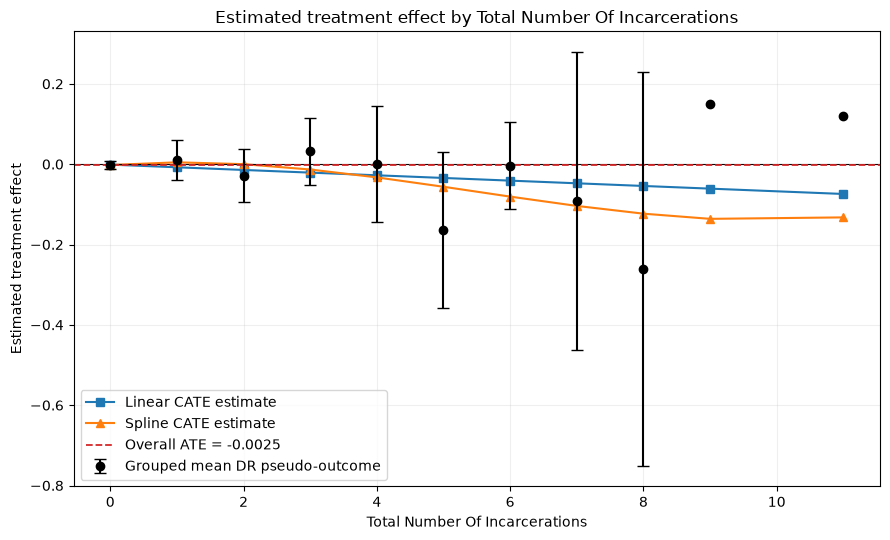

days_r_absent_from_school
Apparent linear pseudo-R²: 0.00015
Apparent spline pseudo-R²: 0.00045


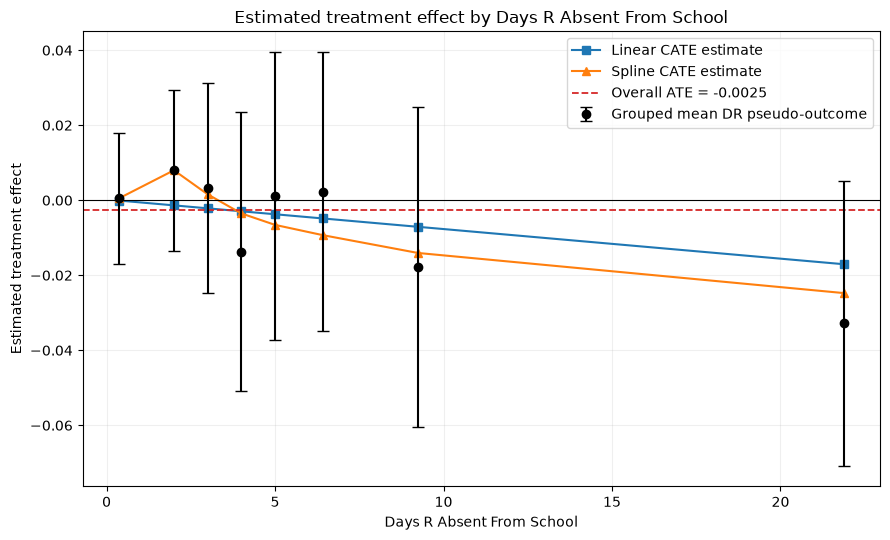

r_threatened_to_be_hurt_at_school
Apparent linear pseudo-R²: 0.00000
Apparent spline pseudo-R²: 0.00032


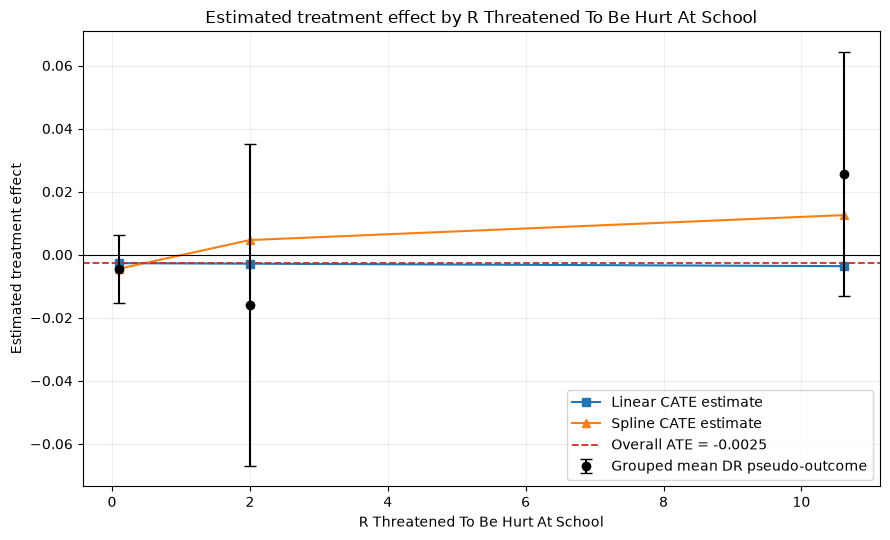

r_in_a_fight_at_school
Apparent linear pseudo-R²: 0.00005
Apparent spline pseudo-R²: 0.00015


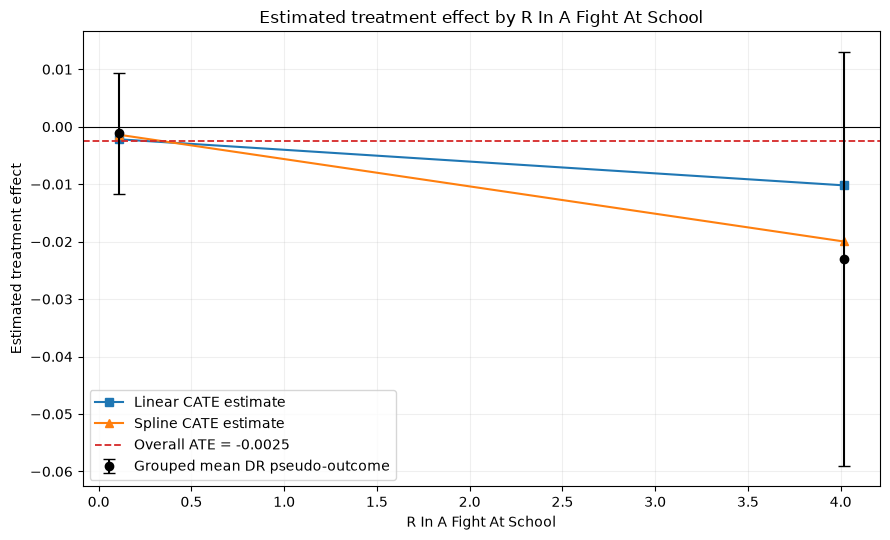

household_net_worth
Apparent linear pseudo-R²: 0.00079
Apparent spline pseudo-R²: 0.00128


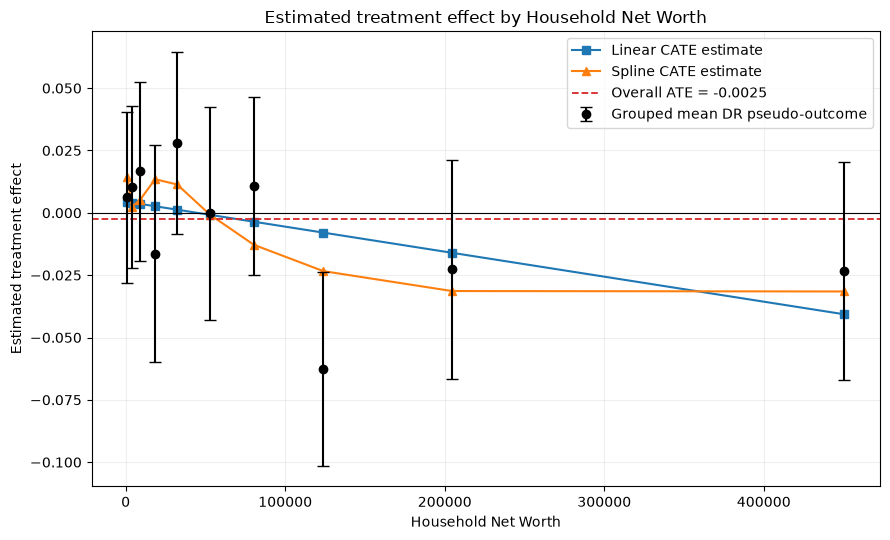

household_size
Apparent linear pseudo-R²: 0.00064
Apparent spline pseudo-R²: 0.00098


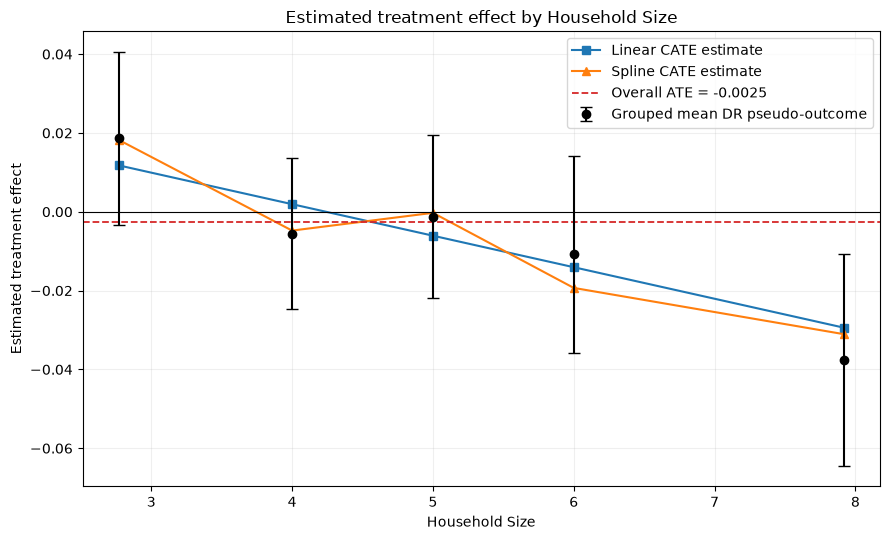

asvab_math_verbal_score_percent
Apparent linear pseudo-R²: 0.00003
Apparent spline pseudo-R²: 0.00102


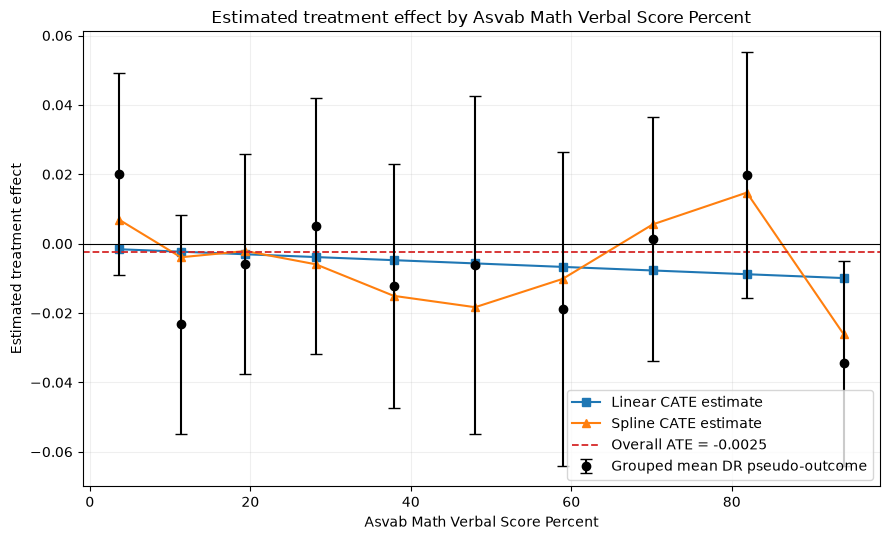

In [21]:
def numeric_plot_table(
    variable,
    number_of_bins=10,
):
    valid = analysis[variable].notna()

    work = pd.DataFrame({
        "x": analysis.loc[
            valid,
            variable,
        ],
        "dr_primary": analysis.loc[
            valid,
            "dr_primary",
        ],
        "linear_prediction": (
            numeric_results[variable][
                "linear"
            ]["mean_prediction"][valid]
        ),
        "spline_prediction": (
            numeric_results[variable][
                "spline"
            ]["mean_prediction"][valid]
        ),
    })

    n_unique = work["x"].nunique()

    if n_unique <= 12:
        work["plot_group"] = work["x"]
    else:
        work["plot_group"] = pd.qcut(
            work["x"],
            q=min(
                number_of_bins,
                n_unique,
            ),
            duplicates="drop",
        )

    table = (
        work
        .groupby(
            "plot_group",
            observed=True,
        )
        .agg(
            n=("dr_primary", "size"),
            x_mean=("x", "mean"),
            observed_DR_mean=(
                "dr_primary",
                "mean",
            ),
            observed_DR_sd=(
                "dr_primary",
                "std",
            ),
            linear_CATE=(
                "linear_prediction",
                "mean",
            ),
            spline_CATE=(
                "spline_prediction",
                "mean",
            ),
        )
        .reset_index(drop=True)
    )

    table["observed_DR_se"] = (
        table["observed_DR_sd"]
        / np.sqrt(table["n"])
    )

    table["ci_lower"] = (
        table["observed_DR_mean"]
        - 1.96
        * table["observed_DR_se"]
    )

    table["ci_upper"] = (
        table["observed_DR_mean"]
        + 1.96
        * table["observed_DR_se"]
    )

    return table


def plot_numeric_cate(variable):
    table = numeric_plot_table(
        variable
    )

    fig, ax = plt.subplots(
        figsize=(9, 5.5)
    )

    ax.errorbar(
        table["x_mean"],
        table["observed_DR_mean"],
        yerr=[
            (
                table["observed_DR_mean"]
                - table["ci_lower"]
            ),
            (
                table["ci_upper"]
                - table["observed_DR_mean"]
            ),
        ],
        fmt="o",
        color="black",
        capsize=4,
        label="Grouped mean DR pseudo-outcome",
        zorder=4,
    )

    ax.plot(
        table["x_mean"],
        table["linear_CATE"],
        marker="s",
        color="tab:blue",
        label="Linear CATE estimate",
    )

    ax.plot(
        table["x_mean"],
        table["spline_CATE"],
        marker="^",
        color="tab:orange",
        label="Spline CATE estimate",
    )

    ax.axhline(
        0,
        color="black",
        linewidth=0.8,
    )

    ax.axhline(
        OVERALL_ATE,
        color="tab:red",
        linestyle="--",
        linewidth=1.3,
        label=(
            f"Overall ATE = "
            f"{OVERALL_ATE:.4f}"
        ),
    )

    readable_name = (
        variable
        .replace("_", " ")
        .title()
    )

    ax.set_title(
        f"Estimated treatment effect by "
        f"{readable_name}"
    )

    ax.set_xlabel(readable_name)

    ax.set_ylabel(
        "Estimated treatment effect"
    )

    ax.legend()
    ax.grid(alpha=0.20)

    plt.tight_layout()
    plt.show()


for variable in numeric_features:
    row = numeric_model_comparison.loc[
        numeric_model_comparison[
            "variable"
        ] == variable
    ].iloc[0]

    print("=" * 80)
    print(variable)

    print(
        "Apparent linear pseudo-R²: "
        f"{row['linear_apparent_pseudo_R2']:.5f}"
    )

    print(
        "Apparent spline pseudo-R²: "
        f"{row['spline_apparent_pseudo_R2']:.5f}"
    )

    plot_numeric_cate(variable)

In [22]:
categorical_results = {}
categorical_comparison_rows = []

for variable in all_categorical_features:
    print(f"Fitting: {variable}")

    X_variable = (
        analysis[[variable]]
        .astype("string")
        .fillna("Missing")
        .astype(str)
    )

    valid_mask = np.ones(
        len(analysis),
        dtype=bool,
    )

    result = fit_second_stage(
        X=X_variable,
        valid_mask=valid_mask,
        model=make_factor_model(),
    )

    categorical_results[
        variable
    ] = result

    counts = (
        X_variable[variable]
        .value_counts()
    )

    categorical_comparison_rows.append({
        "variable": variable,
        "n_levels": (
            X_variable[variable]
            .nunique()
        ),
        "smallest_level_n": counts.min(),
        "model_MSE": result[
            "model_MSE"
        ],
        "baseline_MSE": result[
            "baseline_MSE"
        ],
        "apparent_pseudo_R2": result[
            "apparent_pseudo_R2"
        ],
    })

categorical_model_comparison = (
    pd.DataFrame(
        categorical_comparison_rows
    )
    .sort_values(
        "apparent_pseudo_R2",
        ascending=False,
    )
)

display(
    categorical_model_comparison.round(6)
)

print(
    "These pseudo-R² values are apparent/in-sample."
)

Fitting: teachers_good
Fitting: discipline_is_fair_agree_disagree
Fitting: percent_of_peers_who_smoke
Fitting: percent_of_peers_who_get_drunk_1_times_a_month
Fitting: percent_of_peers_belong_to_a_gang
Fitting: percent_of_peers_who_have_had_sex
Fitting: biological_father_education
Fitting: biological_mother_education
Fitting: bullying_victim_before_age_12
Fitting: r_victim_of_bullying_12_18_years
Fitting: earliest_arrest_before_18
Fitting: sex
Fitting: r_ever_live_through_hard_times
Fitting: race_ethnicity
Fitting: mother_serve_prison_sentence
Fitting: father_serve_prison_sentence


,variable,n_levels,smallest_level_n,model_MSE,baseline_MSE,apparent_pseudo_R2
6,biological_father_education,22,1,0.236268,0.236754,0.002054
7,biological_mother_education,22,6,0.236298,0.236754,0.001926
14,mother_serve_prison_sentence,3,94,0.236479,0.236754,0.001159
11,sex,2,4330,0.236597,0.236754,0.000661
2,percent_of_peers_who_smoke,6,110,0.236600,0.236754,0.000650
5,percent_of_peers_who_have_had_sex,6,537,0.236614,0.236754,0.000590
4,percent_of_peers_belong_to_a_gang,6,170,0.236619,0.236754,0.000569
1,discipline_is_fair_agree_disagree,5,39,0.236633,0.236754,0.000510
15,father_serve_prison_sentence,3,430,0.236660,0.236754,0.000395
13,race_ethnicity,5,156,0.236669,0.236754,0.000357


These pseudo-R² values are apparent/in-sample.


In [23]:
X_rf = analysis[
    all_features
].copy()

for variable in all_categorical_features:
    X_rf[variable] = (
        X_rf[variable]
        .astype("string")
        .fillna("Missing")
        .astype(str)
    )


rf_preprocessor = ColumnTransformer([
    (
        "numeric",
        Pipeline([
            (
                "impute",
                SimpleImputer(
                    strategy="median",
                    add_indicator=True,
                ),
            ),
        ]),
        numeric_features,
    ),
    (
        "categorical",
        Pipeline([
            (
                "one_hot",
                OneHotEncoder(
                    handle_unknown=(
                        "infrequent_if_exist"
                    ),
                    min_frequency=20,
                ),
            ),
        ]),
        all_categorical_features,
    ),
])

rf_model = Pipeline([
    (
        "preprocessor",
        rf_preprocessor,
    ),
    (
        "forest",
        RandomForestRegressor(
            n_estimators=500,
            min_samples_leaf=100,
            max_features=0.70,
            random_state=2026,
            n_jobs=-1,
        ),
    ),
])

rf_target = analysis[
    "dr_primary"
].to_numpy(dtype=float)

rf_model.fit(
    X_rf,
    rf_target,
)

rf_prediction = rf_model.predict(
    X_rf
)

analysis["cate_rf_all"] = (
    rf_prediction
)

rf_model_mse = mean_squared_error(
    rf_target,
    rf_prediction,
)

rf_baseline_prediction = np.repeat(
    OVERALL_ATE,
    len(analysis),
)

rf_baseline_mse = mean_squared_error(
    rf_target,
    rf_baseline_prediction,
)

rf_apparent_pseudo_r2 = (
    1
    - rf_model_mse
    / rf_baseline_mse
)

rf_performance = pd.DataFrame([{
    "model": ACTIVE_MODEL,
    "RF_MSE": rf_model_mse,
    "baseline_MSE": rf_baseline_mse,
    "apparent_pseudo_R2": (
        rf_apparent_pseudo_r2
    ),
}])

display(
    rf_performance.round(6)
)

print(
    "This RF pseudo-R² is apparent/in-sample."
)


# ============================================================
# PERMUTATION IMPORTANCE ON THE FITTED SAMPLE
# ============================================================

importance_rows = []

for variable_position, variable in enumerate(
    all_features
):
    print(f"Permuting: {variable}")

    for permutation in range(
        N_PERMUTATIONS
    ):
        X_permuted = X_rf.copy()

        rng = np.random.default_rng(
            2026
            + variable_position * 1_000
            + permutation
        )

        X_permuted[variable] = (
            rng.permutation(
                X_permuted[
                    variable
                ].to_numpy()
            )
        )

        permuted_prediction = (
            rf_model.predict(
                X_permuted
            )
        )

        permuted_mse = mean_squared_error(
            rf_target,
            permuted_prediction,
        )

        importance_rows.append({
            "variable": variable,
            "permutation": permutation,
            "importance": (
                permuted_mse
                - rf_model_mse
            ),
        })

importance_raw = pd.DataFrame(
    importance_rows
)

importance_summary = (
    importance_raw
    .groupby("variable")["importance"]
    .agg(
        mean_importance="mean",
        sd_importance="std",
        median_importance="median",
        proportion_positive=lambda x:
            (x > 0).mean(),
    )
    .reset_index()
    .sort_values(
        "mean_importance",
        ascending=False,
    )
)

display(
    importance_summary.round(7)
)

,model,RF_MSE,baseline_MSE,apparent_pseudo_R2
0,random_forest,0.228919,0.236754,0.033091


This RF pseudo-R² is apparent/in-sample.
Permuting: total_number_of_incarcerations
Permuting: days_r_absent_from_school
Permuting: r_threatened_to_be_hurt_at_school
Permuting: r_in_a_fight_at_school
Permuting: household_net_worth
Permuting: household_size
Permuting: asvab_math_verbal_score_percent
Permuting: teachers_good
Permuting: discipline_is_fair_agree_disagree
Permuting: percent_of_peers_who_smoke
Permuting: percent_of_peers_who_get_drunk_1_times_a_month
Permuting: percent_of_peers_belong_to_a_gang
Permuting: percent_of_peers_who_have_had_sex
Permuting: biological_father_education
Permuting: biological_mother_education
Permuting: bullying_victim_before_age_12
Permuting: r_victim_of_bullying_12_18_years
Permuting: earliest_arrest_before_18
Permuting: sex
Permuting: r_ever_live_through_hard_times
Permuting: race_ethnicity
Permuting: mother_serve_prison_sentence
Permuting: father_serve_prison_sentence


,variable,mean_importance,sd_importance,median_importance,proportion_positive
8,household_net_worth,0.002920,0.000124,0.002952,1.0
4,days_r_absent_from_school,0.001832,0.000101,0.001853,1.0
0,asvab_math_verbal_score_percent,0.001651,0.000054,0.001661,1.0
10,mother_serve_prison_sentence,0.001305,0.000133,0.001310,1.0
5,discipline_is_fair_agree_disagree,0.001236,0.000120,0.001219,1.0
9,household_size,0.001107,0.000072,0.001112,1.0
20,sex,0.001030,0.000099,0.001031,1.0
14,percent_of_peers_who_smoke,0.000879,0.000047,0.000883,1.0
2,biological_mother_education,0.000823,0.000068,0.000839,1.0
1,biological_father_education,0.000742,0.000039,0.000746,1.0


In [24]:
def calibration_table(
    prediction,
    observed_score,
    number_of_groups=5,
):
    work = pd.DataFrame({
        "prediction": prediction,
        "observed_score": observed_score,
    })

    work["prediction_rank"] = (
        work["prediction"]
        .rank(method="first")
    )

    work["CATE_group"] = pd.qcut(
        work["prediction_rank"],
        q=number_of_groups,
        labels=[
            f"Q{index}"
            for index in range(
                1,
                number_of_groups + 1
            )
        ],
    )

    table = (
        work
        .groupby(
            "CATE_group",
            observed=True,
        )
        .agg(
            n=("observed_score", "size"),
            mean_predicted_CATE=(
                "prediction",
                "mean",
            ),
            mean_DR_score=(
                "observed_score",
                "mean",
            ),
            sd_DR_score=(
                "observed_score",
                "std",
            ),
        )
        .reset_index()
    )

    table["se_DR_mean"] = (
        table["sd_DR_score"]
        / np.sqrt(table["n"])
    )

    table["ci_lower"] = (
        table["mean_DR_score"]
        - 1.96 * table["se_DR_mean"]
    )

    table["ci_upper"] = (
        table["mean_DR_score"]
        + 1.96 * table["se_DR_mean"]
    )

    return table


rf_calibration = calibration_table(
    prediction=analysis[
        "cate_rf_all"
    ],
    observed_score=analysis[
        "dr_primary"
    ],
)

display(
    rf_calibration.round(6)
)

print(
    "This is apparent/in-sample calibration."
)

,CATE_group,n,mean_predicted_CATE,mean_DR_score,sd_DR_score,se_DR_mean,ci_lower,ci_upper
0,Q1,1777,-0.046540,-0.175207,0.650699,0.015436,-0.205462,-0.144952
1,Q2,1777,-0.017453,-0.045644,0.357064,0.008470,-0.062246,-0.029042
2,Q3,1776,-0.000946,-0.014994,0.297251,0.007053,-0.028819,-0.001169
3,Q4,1777,0.014552,0.036305,0.316380,0.007505,0.021595,0.051016
4,Q5,1777,0.038725,0.187055,0.612921,0.014540,0.158557,0.215553


This is apparent/in-sample calibration.


In [25]:
if SAVE_OUTPUTS:
    safe_model_name = (
        ACTIVE_MODEL
        .replace(" ", "_")
        .lower()
    )

    numeric_model_comparison.to_csv(
        OUTPUT_DIR
        / (
            f"cate_{safe_model_name}_"
            "numeric_comparison.csv"
        ),
        index=False,
    )

    categorical_model_comparison.to_csv(
        OUTPUT_DIR
        / (
            f"cate_{safe_model_name}_"
            "categorical_comparison.csv"
        ),
        index=False,
    )

    rf_performance.to_csv(
        OUTPUT_DIR
        / (
            f"cate_{safe_model_name}_"
            "rf_performance.csv"
        ),
        index=False,
    )

    importance_summary.to_csv(
        OUTPUT_DIR
        / (
            f"cate_{safe_model_name}_"
            "rf_importance.csv"
        ),
        index=False,
    )

    rf_calibration.to_csv(
        OUTPUT_DIR
        / (
            f"cate_{safe_model_name}_"
            "rf_calibration.csv"
        ),
        index=False,
    )

    respondent_output = analysis[
        [
            ID_COL,
            "model",
            "Z",
            "R",
            "mu1_minus_mu0",
            "phi_i",
            "dr_primary",
        ]
    ].copy()

    for variable in numeric_features:
        respondent_output[
            f"linear_{variable}"
        ] = numeric_results[
            variable
        ]["linear"]["mean_prediction"]

        respondent_output[
            f"spline_{variable}"
        ] = numeric_results[
            variable
        ]["spline"]["mean_prediction"]

    for variable in all_categorical_features:
        respondent_output[
            f"factor_{variable}"
        ] = categorical_results[
            variable
        ]["mean_prediction"]

    respondent_output[
        "cate_rf_all"
    ] = analysis[
        "cate_rf_all"
    ]

    respondent_output.to_csv(
        OUTPUT_DIR
        / (
            f"cate_{safe_model_name}_"
            "respondent_estimates.csv"
        ),
        index=False,
    )

    print(
        f"Saved outputs for model: "
        f"{ACTIVE_MODEL}"
    )

Saved outputs for model: random_forest
